<a href="https://colab.research.google.com/github/kalyanisingh19196-netizen/Neural-Networks-and-Deep-Learning-Lab/blob/main/Assignment-3-Optimization/gradient_descent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

BATCH GRADIENT DESCENT
Weight: 3.0033498956685407
Bias: 1.89381711248117
Final Loss: 0.835886583280322

STOCHASTIC GRADIENT DESCENT
Weight: 3.0747659835895154
Bias: 2.2211689871849525
Final Loss: 1.2635466995359979

MINI-BATCH GRADIENT DESCENT
Weight: 2.9965193011407756
Bias: 2.20278275954737
Final Loss: 0.8575628291181823


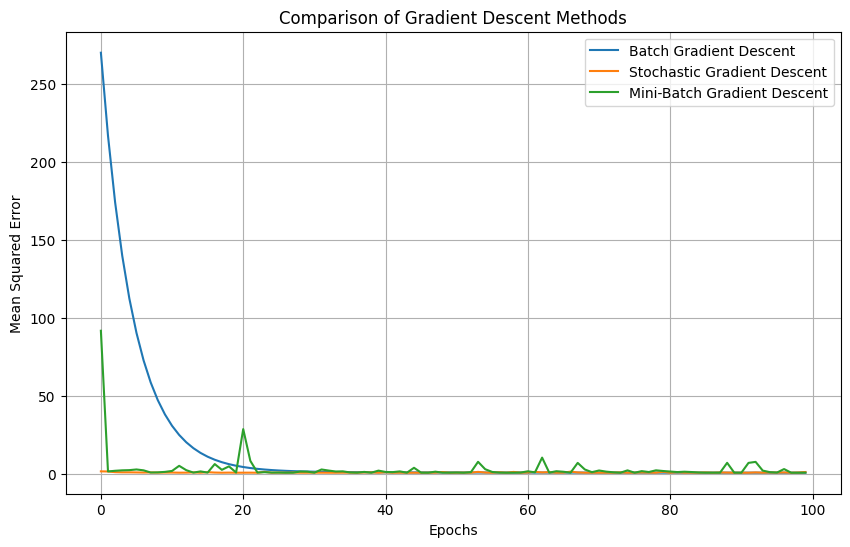

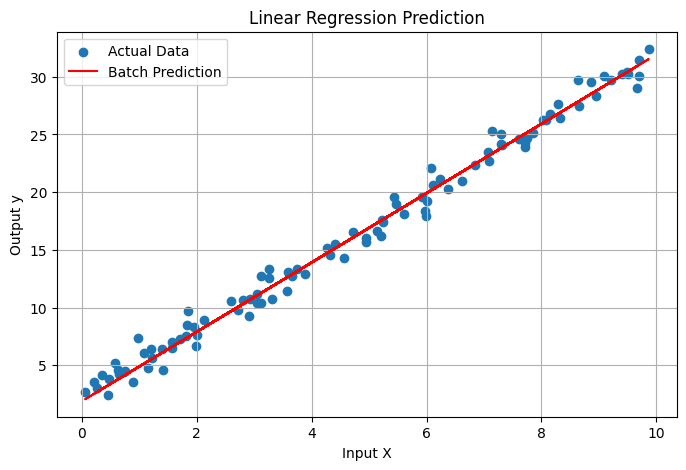

In [1]:
# Gradient Descent: Batch, Stochastic and Mini-Batch
# Assignment 3 - Optimization Techniques

import numpy as np
import matplotlib.pyplot as plt

# 1. Generate a sample dataset
np.random.seed(42)

X = np.random.rand(100, 1) * 10
y = 3 * X + 2 + np.random.randn(100, 1)

# 2. Gradient Descent function
def gradient_descent(X, y, method, epochs=100, learning_rate=0.03,
                     batch_size=16):

    m = len(X)

    w = np.zeros((1, 1))
    b = 0.0

    losses = []

    for epoch in range(epochs):

        # Shuffle data for SGD and Mini-Batch
        indices = np.random.permutation(m)
        X_shuffled = X[indices]
        y_shuffled = y[indices]

        if method == "Batch":
            batches = [(X_shuffled, y_shuffled)]

        elif method == "Stochastic":
            batches = [
                (X_shuffled[i:i+1], y_shuffled[i:i+1])
                for i in range(m)
            ]

        elif method == "Mini-Batch":
            batches = [
                (X_shuffled[i:i+batch_size],
                 y_shuffled[i:i+batch_size])
                for i in range(0, m, batch_size)
            ]

        # Update weights and bias
        for X_batch, y_batch in batches:

            predictions = X_batch @ w + b
            error = predictions - y_batch

            dw = (2 / len(X_batch)) * (X_batch.T @ error)
            db = (2 / len(X_batch)) * np.sum(error)

            w = w - learning_rate * dw
            b = b - learning_rate * db

        # Calculate full dataset loss after each epoch
        predictions = X @ w + b
        loss = np.mean((predictions - y) ** 2)

        losses.append(loss)

    return w, b, losses


# 3. Train using all three methods
w_batch, b_batch, loss_batch = gradient_descent(
    X, y, "Batch"
)

w_sgd, b_sgd, loss_sgd = gradient_descent(
    X, y, "Stochastic", learning_rate=0.003
)

w_mini, b_mini, loss_mini = gradient_descent(
    X, y, "Mini-Batch"
)


# 4. Display final results
print("BATCH GRADIENT DESCENT")
print("Weight:", w_batch[0][0])
print("Bias:", b_batch)
print("Final Loss:", loss_batch[-1])

print("\nSTOCHASTIC GRADIENT DESCENT")
print("Weight:", w_sgd[0][0])
print("Bias:", b_sgd)
print("Final Loss:", loss_sgd[-1])

print("\nMINI-BATCH GRADIENT DESCENT")
print("Weight:", w_mini[0][0])
print("Bias:", b_mini)
print("Final Loss:", loss_mini[-1])


# 5. Compare the loss curves
plt.figure(figsize=(10, 6))

plt.plot(loss_batch, label="Batch Gradient Descent")
plt.plot(loss_sgd, label="Stochastic Gradient Descent")
plt.plot(loss_mini, label="Mini-Batch Gradient Descent")

plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.title("Comparison of Gradient Descent Methods")

plt.legend()
plt.grid(True)
plt.show()


# 6. Compare actual and predicted values
plt.figure(figsize=(8, 5))

plt.scatter(X, y, label="Actual Data")

plt.plot(X, X @ w_batch + b_batch,
         color="red", label="Batch Prediction")

plt.xlabel("Input X")
plt.ylabel("Output y")
plt.title("Linear Regression Prediction")

plt.legend()
plt.grid(True)
plt.show()